In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools


from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # type: ignore



In [2]:
import sys
print(sys.executable)


c:\Users\danie\Desktop\My_Things\Hobbies\VSCODE\Virtual Envorinments\Ai-3d-Reconstruction-0.1\.venv\Scripts\python.exe


In [ ]:
from pathlib import Path

from utils.path_loader import load_paths
paths = load_paths()

PROJECT_ROOT = paths["project_root"]
print(PROJECT_ROOT)

from data_sets.dataset import build_dataset

C:\Users\danie\Desktop\My_Things\Hobbies\VSCODE\Virtual Envorinments\Ai-3d-Reconstruction-0.1


In [ ]:
# Pastas de treino
TRAIN_RANDOM_IMAGES = paths["train_random_images"]
TRAIN_VIDEO_IMAGES = paths["train_video_images"]

# Ficheiros CSV para os dataframes
OUTPUT_CSV_RANDOM_IMAGES = PROJECT_ROOT / "data"/ "datasets" / "random_images_features.csv"
OUTPUT_CSV_VIDEO1_IMAGES = PROJECT_ROOT / "video1"/"data"/ "datasets" / "video1_images_features.csv"

# Gráficos obtidos
OUTPUT_GRAPHICS = PROJECT_ROOT / "data"/ "graphics" / "matriz_de_correlação"
OUTPUT_GRAPHICS_CORR = OUTPUT_GRAPHICS / "matriz_de_correlação"


# Step 1: Load and Explore the Data

### 1.1 Create Dataset

Dataframe do Random Images


In [ ]:
df_random_images = build_dataset(
    images_dir=TRAIN_RANDOM_IMAGES,
    output_csv=OUTPUT_CSV_RANDOM_IMAGES,
    with_label=True,
    feature_set = "both"
)


print("Dataset criado com sucesso!")
print("Shape:", df_random_images.shape)
df_random_images.head(10)

Processando bad_images: 700it [2:02:05, 10.46s/it]
Processando good_images: 350it [1:02:41, 10.75s/it]
Processando custom_images: 133it [00:28,  4.70it/s]


Dataset criado com sucesso!
Shape: (1182, 207)


,image_path,label,q_quality_laplacian_var,q_quality_fft_energy,q_quality_motion_dominance,q_quality_local_laplacian_mean,q_quality_local_laplacian_std,q_quality_contrast_energy,q_quality_tenengrad_energy,q_quality_log_quantile,...,c_orb_desc_std_022,c_orb_desc_std_023,c_orb_desc_std_024,c_orb_desc_std_025,c_orb_desc_std_026,c_orb_desc_std_027,c_orb_desc_std_028,c_orb_desc_std_029,c_orb_desc_std_030,c_orb_desc_std_031
0,C:\Users\danie\Desktop\My_Things\Hobbies\VSCOD...,1,9.014649,3.991950,1.446499,9.166742,4.711643,9.337106,131.751382,8.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,C:\Users\danie\Desktop\My_Things\Hobbies\VSCOD...,1,14.389066,5.991028,2.080324,15.588547,29.209121,11.524235,391.821008,16.0,...,69.443626,76.637413,59.474754,65.763542,71.012070,55.736332,70.923172,72.858215,66.117065,70.074295
2,C:\Users\danie\Desktop\My_Things\Hobbies\VSCOD...,1,40.653312,3.625680,1.205840,43.957331,26.885645,14.149989,307.320198,34.0,...,106.024925,29.707472,99.746651,92.654076,34.183960,32.724247,84.350624,74.274681,38.036854,38.392063
3,C:\Users\danie\Desktop\My_Things\Hobbies\VSCOD...,1,74.782909,6.673167,1.934117,82.183000,226.162931,17.897213,1317.031408,32.0,...,81.524796,85.256378,73.897202,75.538116,74.995537,72.516205,67.322601,76.194122,68.542061,72.951729
4,C:\Users\danie\Desktop\My_Things\Hobbies\VSCOD...,1,39.192811,2.761587,1.209337,42.360634,20.677822,14.108409,283.032814,39.0,...,37.500000,29.000000,34.000000,47.500000,81.000000,62.000000,103.500000,51.500000,127.500000,82.500000
5,C:\Users\danie\Desktop\My_Things\Hobbies\VSCOD...,1,42.025393,3.098964,1.195735,45.543690,25.007773,14.742769,329.874117,41.0,...,73.642616,97.847656,66.230217,89.948898,58.173046,74.086929,63.205971,64.452789,58.223602,64.006813
6,C:\Users\danie\Desktop\My_Things\Hobbies\VSCOD...,1,19.412589,3.068970,1.324564,20.730564,13.589973,9.838369,153.503420,49.0,...,104.267616,43.081318,88.842293,91.889130,51.126747,56.055622,67.770798,68.693344,42.570068,74.556641
7,C:\Users\danie\Desktop\My_Things\Hobbies\VSCOD...,1,23.877265,3.271329,1.278472,25.742943,28.075890,10.854444,240.365543,49.0,...,73.563789,87.430069,61.919086,68.226089,66.754883,68.791664,65.710350,72.571449,68.219856,74.715103
8,C:\Users\danie\Desktop\My_Things\Hobbies\VSCOD...,1,13.745478,3.453437,1.761838,14.032975,11.979620,7.758225,99.813141,15.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,C:\Users\danie\Desktop\My_Things\Hobbies\VSCOD...,1,22.969176,8.305311,5.404013,25.201616,43.319161,11.412063,644.931645,26.0,...,82.682945,75.378525,80.495125,72.962776,74.936279,64.813766,63.862644,78.281609,64.783638,67.440544


Ler Dataframes já criados

In [ ]:
df_random_images = pd.read_csv(OUTPUT_CSV_RANDOM_IMAGES)

### 1.2 Variáveis de quality e de clustering

Dividir features para quality e para clustering

In [ ]:
df_random_images.columns.tolist()


['image_path',
 'label',
 'q_quality_laplacian_var',
 'q_quality_fft_energy',
 'q_quality_motion_dominance',
 'q_quality_local_laplacian_mean',
 'q_quality_local_laplacian_std',
 'q_quality_contrast_energy',
 'q_quality_tenengrad_energy',
 'q_quality_log_quantile',
 'q_quality_noise_residual',
 'q_quality_noise_flat',
 'q_quality_noise_fft',
 'q_quality_jpeg_blockiness',
 'q_quality_exposure_clipping',
 'q_quality_dynamic_range',
 'q_center_laplacian_ratio',
 'q_orb_kp_count',
 'q_orb_kp_entropy',
 'q_orb_response_mean',
 'q_orb_size_mean',
 'c_color_hist_hsv_000',
 'c_color_hist_hsv_001',
 'c_color_hist_hsv_002',
 'c_color_hist_hsv_003',
 'c_color_hist_hsv_004',
 'c_color_hist_hsv_005',
 'c_color_hist_hsv_006',
 'c_color_hist_hsv_007',
 'c_color_hist_hsv_008',
 'c_color_hist_hsv_009',
 'c_color_hist_hsv_010',
 'c_color_hist_hsv_011',
 'c_color_hist_hsv_012',
 'c_color_hist_hsv_013',
 'c_color_hist_hsv_014',
 'c_color_hist_hsv_015',
 'c_color_hist_hsv_016',
 'c_color_hist_hsv_017',
 'c

Dividir para o random_images

In [ ]:
df_random_images_quality = df_random_images.loc[
    :,
    ["label", *df_random_images.filter(regex=r"^q_").columns]]

df_random_images_quality.head(20)


,label,q_quality_laplacian_var,q_quality_fft_energy,q_quality_motion_dominance,q_quality_local_laplacian_mean,q_quality_local_laplacian_std,q_quality_contrast_energy,q_quality_tenengrad_energy,q_quality_log_quantile,q_quality_noise_residual,q_quality_noise_flat,q_quality_noise_fft,q_quality_jpeg_blockiness,q_quality_exposure_clipping,q_quality_dynamic_range,q_center_laplacian_ratio,q_orb_kp_count,q_orb_kp_entropy,q_orb_response_mean,q_orb_size_mean
0,1,9.014649,3.991950,1.446499,9.166742,4.711643,9.337106,131.751382,8.0,0.691943,0.789640,5489.377930,186.217188,1.881779e-02,233.00,1.123915,0.0,-0.000000,0.000000,0.000000
1,1,14.389066,5.991028,2.080324,15.588547,29.209121,11.524235,391.821008,16.0,0.876574,0.342043,7213.047852,170.069999,1.686941e-01,222.00,1.835164,49.0,1.612725,0.000011,41.520954
2,1,40.653312,3.625680,1.205840,43.957331,26.885645,14.149989,307.320198,34.0,1.361667,0.588948,11453.166016,198.467950,1.939267e-02,229.00,0.836396,18.0,0.925702,0.000127,77.873497
3,1,74.782909,6.673167,1.934117,82.183000,226.162931,17.897213,1317.031408,32.0,1.910996,0.484950,19396.318359,201.387070,1.748287e-02,248.00,1.628461,800.0,1.459073,0.001607,53.735771
4,1,39.192811,2.761587,1.209337,42.360634,20.677822,14.108409,283.032814,39.0,1.341607,0.531392,10561.070312,200.616275,2.284246e-02,163.00,1.627160,2.0,0.693147,0.000002,31.000000
5,1,42.025393,3.098964,1.195735,45.543690,25.007773,14.742769,329.874117,41.0,1.388474,0.571717,11339.525391,202.256896,1.721962e-02,203.00,1.620586,297.0,0.919128,0.000295,55.212162
6,1,19.412589,3.068970,1.324564,20.730564,13.589973,9.838369,153.503420,49.0,0.969125,0.601164,8558.269531,183.548482,1.088190e-01,166.00,1.338915,19.0,1.113771,0.000119,72.157028
7,1,23.877265,3.271329,1.278472,25.742943,28.075890,10.854444,240.365543,49.0,1.068605,0.769513,9840.045898,187.206259,7.211396e-02,133.00,1.138255,800.0,1.084394,0.000383,53.735771
8,1,13.745478,3.453437,1.761838,14.032975,11.979620,7.758225,99.813141,15.0,0.798359,0.368622,4878.551758,141.679997,1.900114e-01,225.00,0.831370,0.0,-0.000000,0.000000,0.000000
9,1,22.969176,8.305311,5.404013,25.201616,43.319161,11.412063,644.931645,26.0,1.103778,0.578366,7128.179199,168.615227,3.004090e-01,236.00,2.849761,205.0,1.661156,0.000034,56.186241


In [ ]:
df_random_images_clustering = df_random_images.loc[
    :,
    ["label", *df_random_images.filter(regex=r"^c_").columns]]

df_random_images_clustering.head(20)

,label,c_color_hist_hsv_000,c_color_hist_hsv_001,c_color_hist_hsv_002,c_color_hist_hsv_003,c_color_hist_hsv_004,c_color_hist_hsv_005,c_color_hist_hsv_006,c_color_hist_hsv_007,c_color_hist_hsv_008,...,c_orb_desc_std_022,c_orb_desc_std_023,c_orb_desc_std_024,c_orb_desc_std_025,c_orb_desc_std_026,c_orb_desc_std_027,c_orb_desc_std_028,c_orb_desc_std_029,c_orb_desc_std_030,c_orb_desc_std_031
0,1,0.089173,0.210611,0.455002,0.411069,9.038854e-02,0.428636,0.058414,0.048666,0.008659,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1,0.083900,0.213748,0.436178,0.684722,3.061748e-02,0.207026,0.395981,0.242236,0.000801,...,69.443626,76.637413,59.474754,65.763542,71.012070,55.736332,70.923172,72.858215,66.117065,70.074295
2,1,0.233130,0.001207,0.000425,0.018347,1.550940e-01,0.004679,0.000709,0.001467,0.127236,...,106.024925,29.707472,99.746651,92.654076,34.183960,32.724247,84.350624,74.274681,38.036854,38.392063
3,1,0.126985,0.002641,0.000661,0.034005,8.898726e-02,0.005000,0.001055,0.001225,0.043249,...,81.524796,85.256378,73.897202,75.538116,74.995537,72.516205,67.322601,76.194122,68.542061,72.951729
4,1,0.852992,0.004329,0.000341,0.014606,3.459165e-01,0.006826,0.001208,0.003260,0.079217,...,37.500000,29.000000,34.000000,47.500000,81.000000,62.000000,103.500000,51.500000,127.500000,82.500000
5,1,0.889492,0.007525,0.000269,0.015446,2.732682e-01,0.005482,0.002956,0.007890,0.047312,...,73.642616,97.847656,66.230217,89.948898,58.173046,74.086929,63.205971,64.452789,58.223602,64.006813
6,1,0.083754,0.003260,0.000453,0.005357,2.340678e-01,0.001730,0.000353,0.000747,0.367813,...,104.267616,43.081318,88.842293,91.889130,51.126747,56.055622,67.770798,68.693344,42.570068,74.556641
7,1,0.008610,0.003128,0.002647,0.001880,4.501865e-02,0.003082,0.000640,0.000220,0.212117,...,73.563789,87.430069,61.919086,68.226089,66.754883,68.791664,65.710350,72.571449,68.219856,74.715103
8,1,0.002049,0.001709,0.000236,0.302068,4.744787e-03,0.003599,0.002475,0.133487,0.055603,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,1,0.043392,0.006864,0.001194,0.654309,4.195188e-02,0.008698,0.004159,0.180432,0.033678,...,82.682945,75.378525,80.495125,72.962776,74.936279,64.813766,63.862644,78.281609,64.783638,67.440544


### 1.3 Dividir variáveis categóricas e numéricas

Em random_images

In [ ]:
numeric_cols_random = df_random_images_quality.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols_random = df_random_images_quality.select_dtypes(include=['object']).columns.tolist()

numeric_cols_random, categorical_cols_random

(['label',
  'q_quality_laplacian_var',
  'q_quality_fft_energy',
  'q_quality_motion_dominance',
  'q_quality_local_laplacian_mean',
  'q_quality_local_laplacian_std',
  'q_quality_contrast_energy',
  'q_quality_tenengrad_energy',
  'q_quality_log_quantile',
  'q_quality_noise_residual',
  'q_quality_noise_flat',
  'q_quality_noise_fft',
  'q_quality_jpeg_blockiness',
  'q_quality_exposure_clipping',
  'q_quality_dynamic_range',
  'q_center_laplacian_ratio',
  'q_orb_kp_count',
  'q_orb_kp_entropy',
  'q_orb_response_mean',
  'q_orb_size_mean'],
 [])

### 1.4 Verificação de valores “esquisitos” / inválidos (Data sanity checks)

Verificar se existem image_path repetidos

In [ ]:
# No dataset de treino
print(df_random_images['image_path'].duplicated().sum())

0
0


### 1.5 Gráficos

Das distribuição variáveis numéricas

array([[<Axes: title={'center': 'label'}>,
        <Axes: title={'center': 'q_quality_laplacian_var'}>,
        <Axes: title={'center': 'q_quality_fft_energy'}>,
        <Axes: title={'center': 'q_quality_motion_dominance'}>],
       [<Axes: title={'center': 'q_quality_local_laplacian_mean'}>,
        <Axes: title={'center': 'q_quality_local_laplacian_std'}>,
        <Axes: title={'center': 'q_quality_contrast_energy'}>,
        <Axes: title={'center': 'q_quality_tenengrad_energy'}>],
       [<Axes: title={'center': 'q_quality_log_quantile'}>,
        <Axes: title={'center': 'q_quality_noise_residual'}>,
        <Axes: title={'center': 'q_quality_noise_flat'}>,
        <Axes: title={'center': 'q_quality_noise_fft'}>],
       [<Axes: title={'center': 'q_quality_jpeg_blockiness'}>,
        <Axes: title={'center': 'q_quality_exposure_clipping'}>,
        <Axes: title={'center': 'q_quality_dynamic_range'}>,
        <Axes: title={'center': 'q_center_laplacian_ratio'}>],
       [<Axes: title

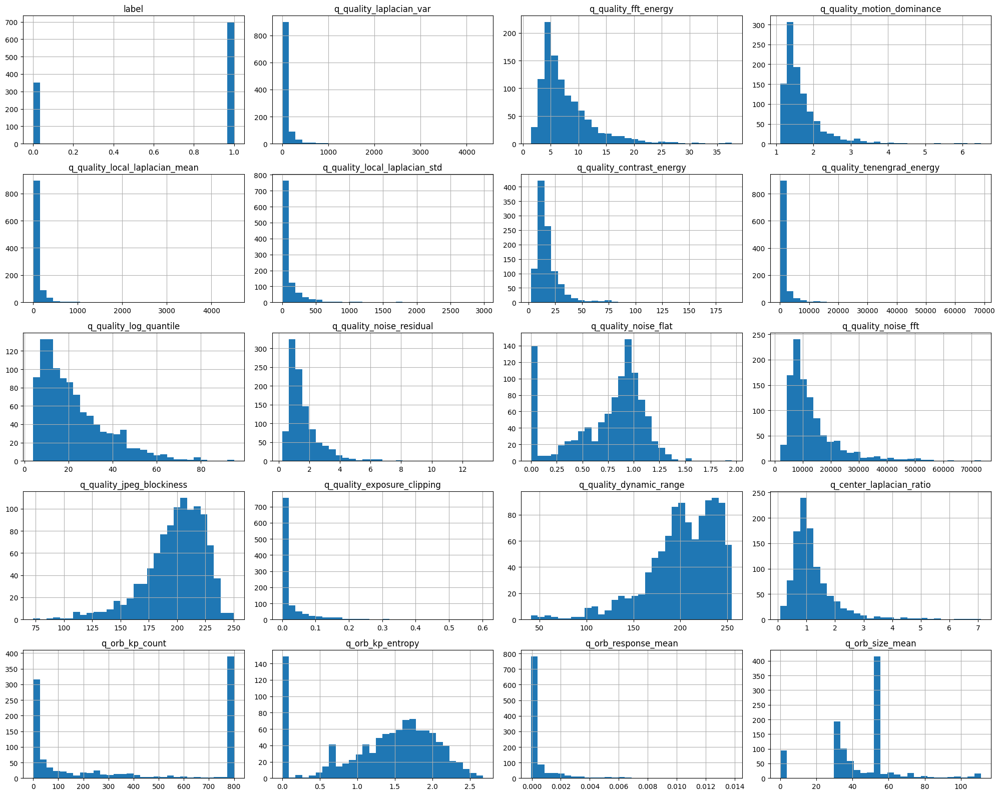

In [ ]:
df_random_images_quality[numeric_cols_random].hist(figsize=(20,16), bins=30)
plt.tight_layout()
plt.show()


Das distribuição variáveis numéricas por cores fica intuitiva:

* **Good → verde** (imagem correta, “ok”)
* **Blurs → azuis** (problemas de foco/movimento)
* **Noisy / Very Noisy → laranja e vermelho** (degradação progressiva)
* **Pixelated → roxo** (tipo de degradação diferente)

Assim, só de olhar para os gráficos já consegues perceber rapidamente que tipo de problema cada grupo representa.


In [ ]:
palette = {
    "Good": "green",

    # Blurs (tons parecidos)
    "Defocused Blur": "royalblue",
    "Motion Blur": "deepskyblue",

    # Ruído (tons quentes parecidos)
    "Noisy": "orange",
    "Very Noisy": "red",

    # Pixelização (roxo)
    "Pixelated": "purple",
}

In [ ]:
# Para as random images
sns.pairplot(
    df_random_images_quality,
    hue="label",
    diag_kind="hist",
    palette=palette,
    height=3.5,
    aspect=1.2
)

plt.show()


Das distribuição variáveis numéricas por label, mais proximo e apenas histogramas

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='label', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of label by Label')

Text(0.5, 0, 'label')

Text(0, 0.5, 'Frequency')

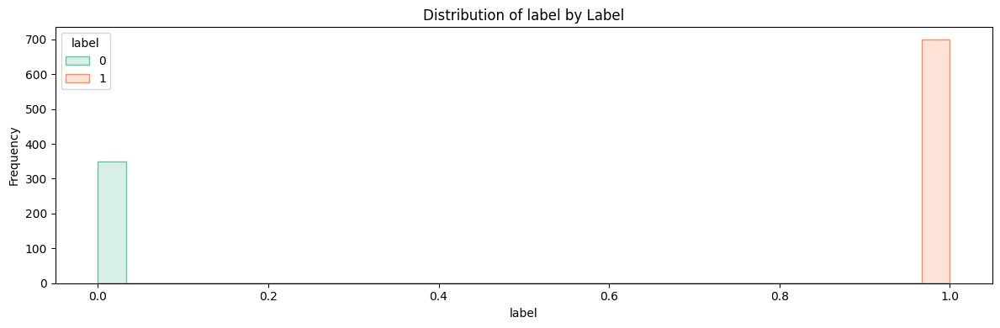

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_laplacian_var', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_laplacian_var by Label')

Text(0.5, 0, 'q_quality_laplacian_var')

Text(0, 0.5, 'Frequency')

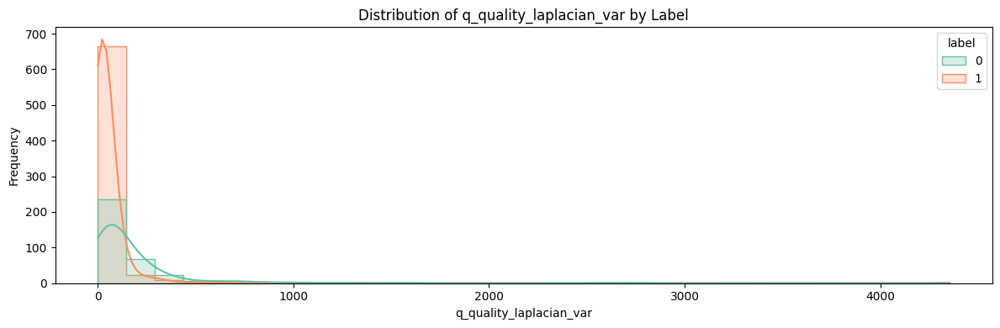

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_fft_energy', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_fft_energy by Label')

Text(0.5, 0, 'q_quality_fft_energy')

Text(0, 0.5, 'Frequency')

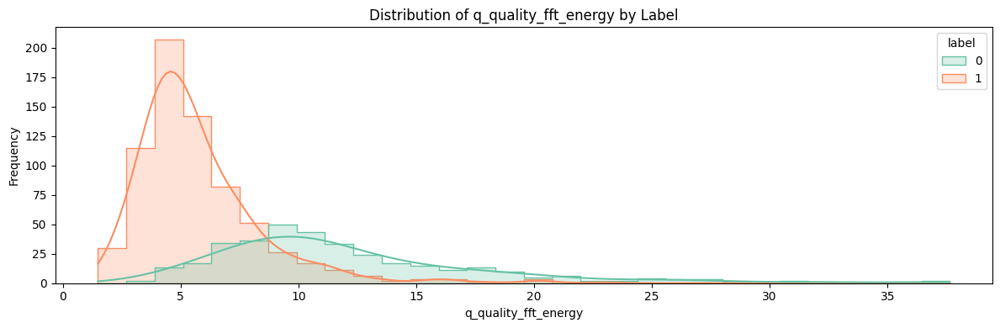

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_motion_dominance', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_motion_dominance by Label')

Text(0.5, 0, 'q_quality_motion_dominance')

Text(0, 0.5, 'Frequency')

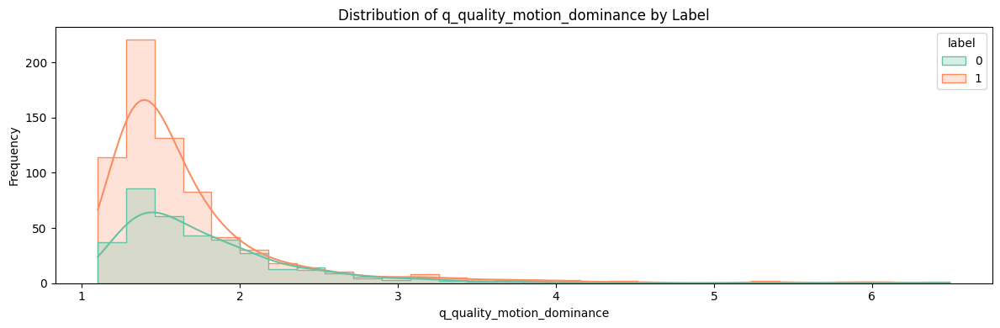

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_local_laplacian_mean', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_local_laplacian_mean by Label')

Text(0.5, 0, 'q_quality_local_laplacian_mean')

Text(0, 0.5, 'Frequency')

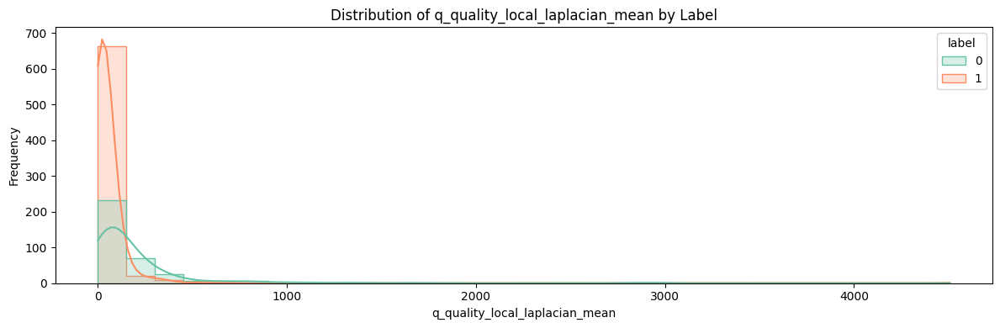

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_local_laplacian_std', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_local_laplacian_std by Label')

Text(0.5, 0, 'q_quality_local_laplacian_std')

Text(0, 0.5, 'Frequency')

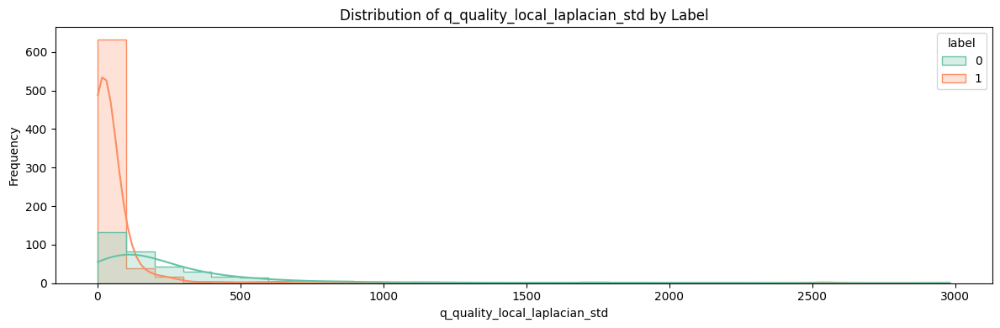

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_contrast_energy', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_contrast_energy by Label')

Text(0.5, 0, 'q_quality_contrast_energy')

Text(0, 0.5, 'Frequency')

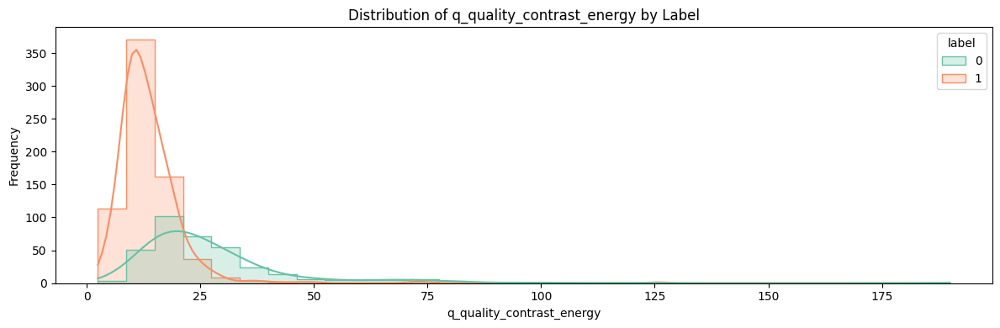

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_tenengrad_energy', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_tenengrad_energy by Label')

Text(0.5, 0, 'q_quality_tenengrad_energy')

Text(0, 0.5, 'Frequency')

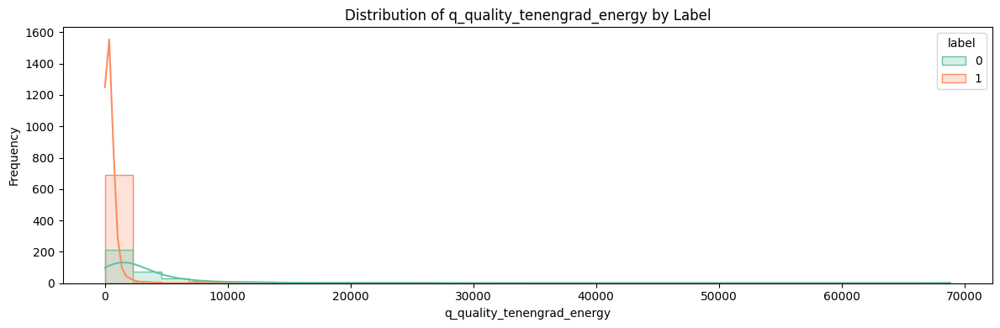

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_log_quantile', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_log_quantile by Label')

Text(0.5, 0, 'q_quality_log_quantile')

Text(0, 0.5, 'Frequency')

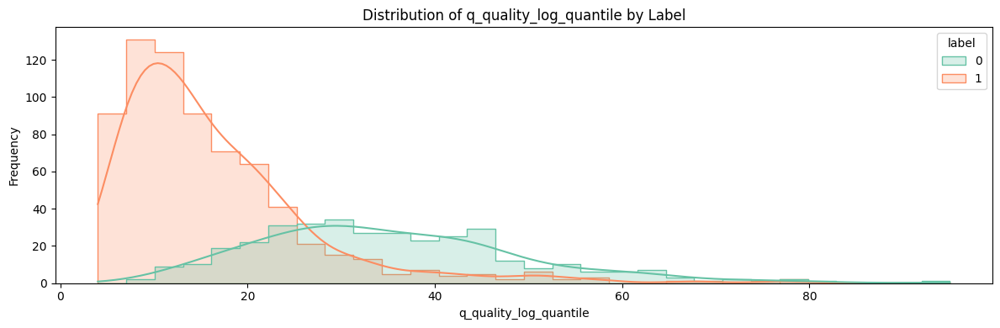

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_noise_residual', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_noise_residual by Label')

Text(0.5, 0, 'q_quality_noise_residual')

Text(0, 0.5, 'Frequency')

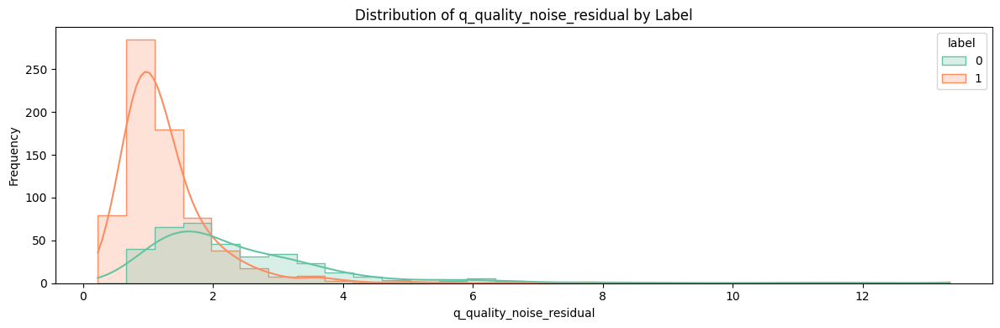

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_noise_flat', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_noise_flat by Label')

Text(0.5, 0, 'q_quality_noise_flat')

Text(0, 0.5, 'Frequency')

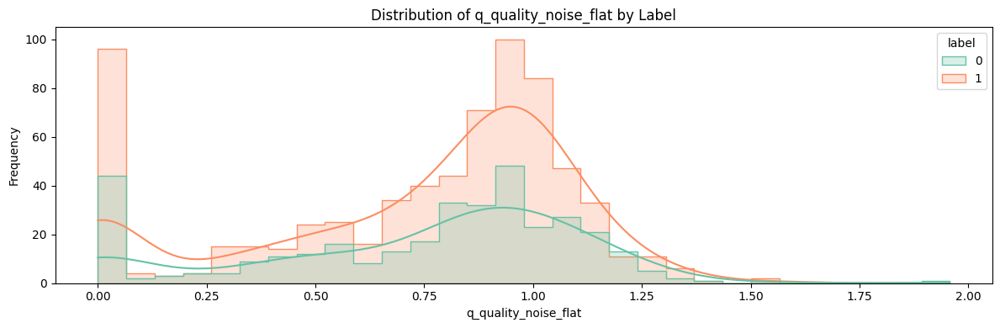

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_noise_fft', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_noise_fft by Label')

Text(0.5, 0, 'q_quality_noise_fft')

Text(0, 0.5, 'Frequency')

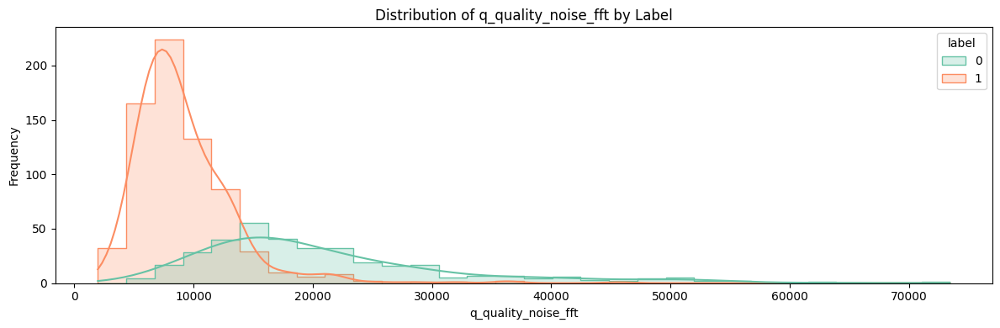

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_jpeg_blockiness', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_jpeg_blockiness by Label')

Text(0.5, 0, 'q_quality_jpeg_blockiness')

Text(0, 0.5, 'Frequency')

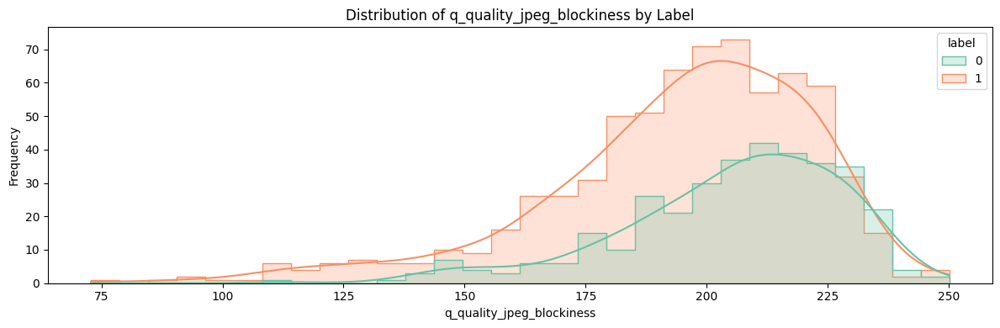

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_exposure_clipping', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_exposure_clipping by Label')

Text(0.5, 0, 'q_quality_exposure_clipping')

Text(0, 0.5, 'Frequency')

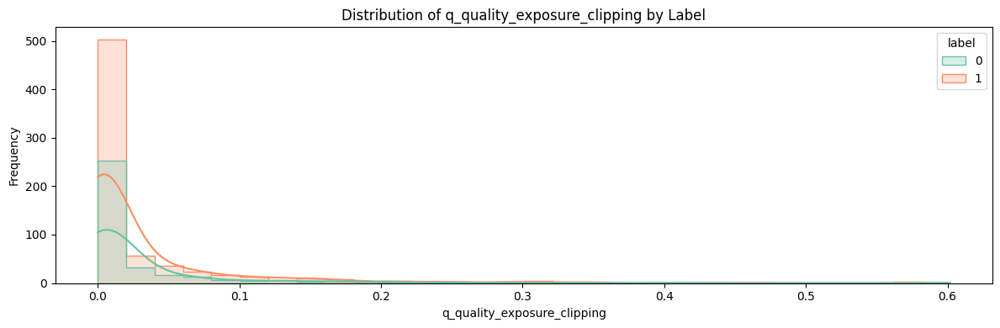

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_quality_dynamic_range', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_quality_dynamic_range by Label')

Text(0.5, 0, 'q_quality_dynamic_range')

Text(0, 0.5, 'Frequency')

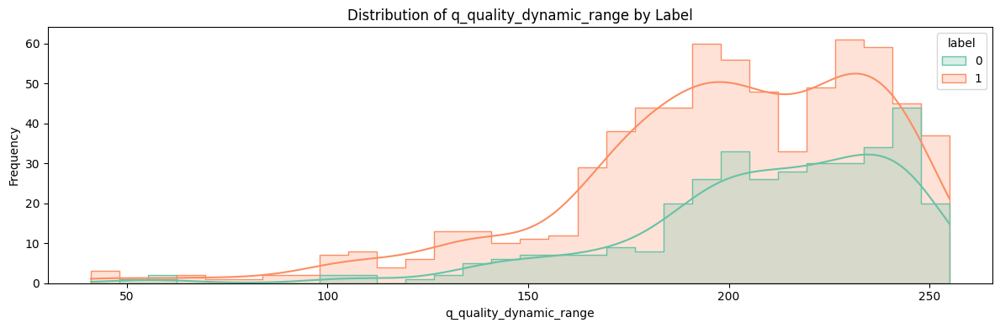

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_center_laplacian_ratio', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_center_laplacian_ratio by Label')

Text(0.5, 0, 'q_center_laplacian_ratio')

Text(0, 0.5, 'Frequency')

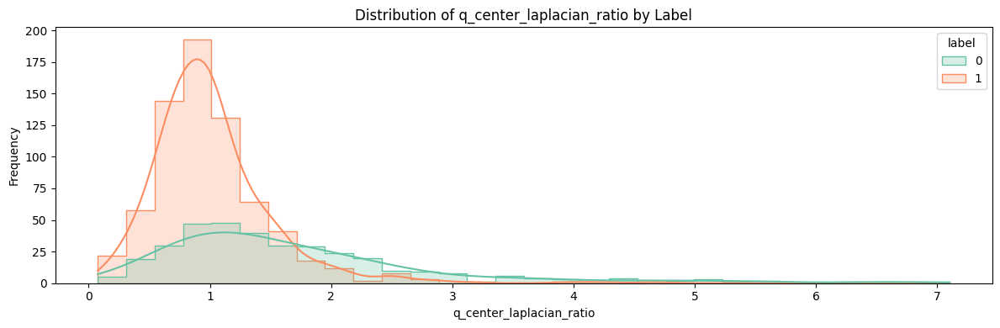

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_orb_kp_count', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_orb_kp_count by Label')

Text(0.5, 0, 'q_orb_kp_count')

Text(0, 0.5, 'Frequency')

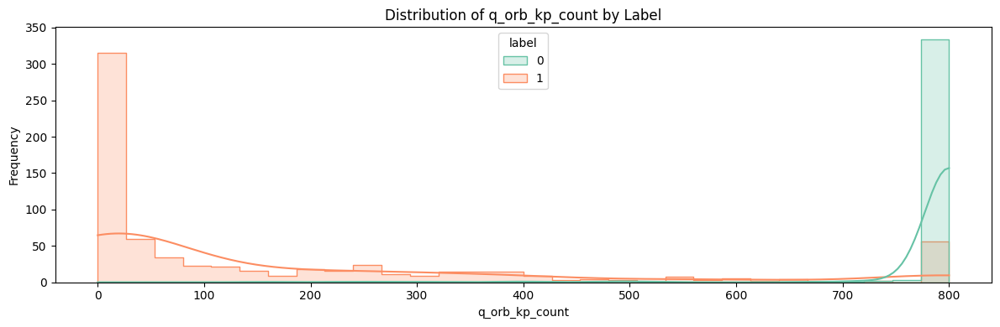

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_orb_kp_entropy', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_orb_kp_entropy by Label')

Text(0.5, 0, 'q_orb_kp_entropy')

Text(0, 0.5, 'Frequency')

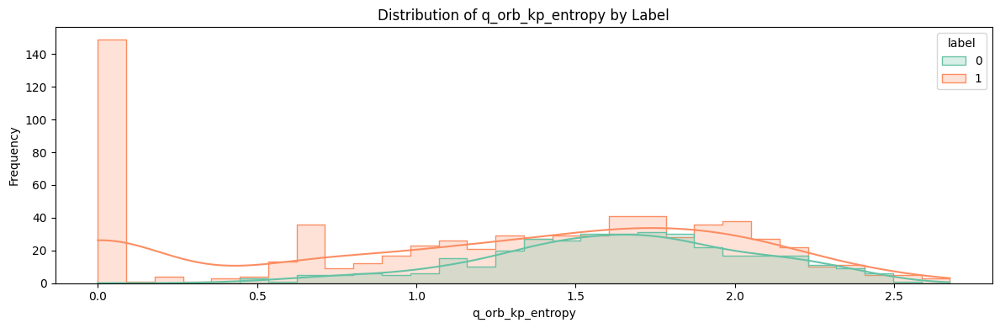

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_orb_response_mean', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_orb_response_mean by Label')

Text(0.5, 0, 'q_orb_response_mean')

Text(0, 0.5, 'Frequency')

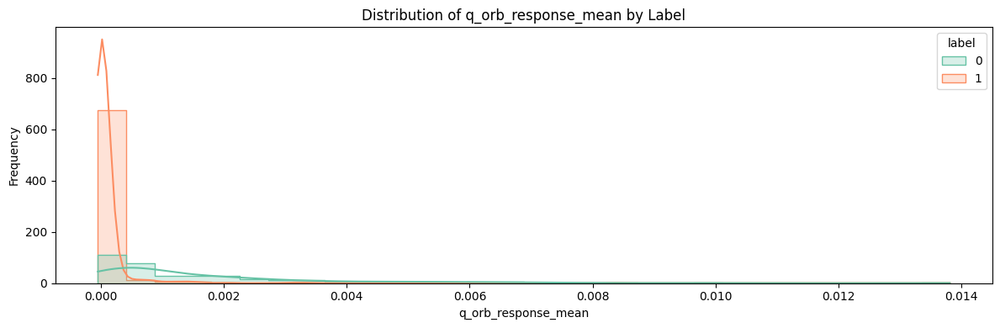

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='q_orb_size_mean', ylabel='Count'>

Text(0.5, 1.0, 'Distribution of q_orb_size_mean by Label')

Text(0.5, 0, 'q_orb_size_mean')

Text(0, 0.5, 'Frequency')

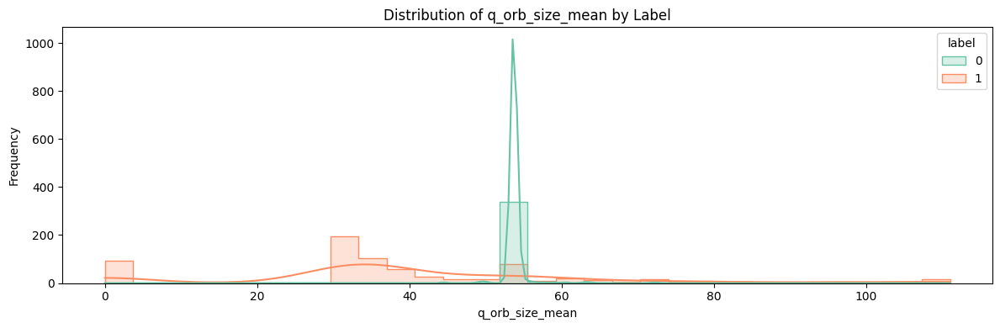

In [ ]:
# Para as random images

for col in numeric_cols_random:
    plt.figure(figsize=(12, 4))

    sns.histplot(
        data=df_random_images_quality,
        x=col,
        hue="label",
        bins=30,
        kde=True,
        element="step",
        palette=palette,
        stat="density",      # para comparar distribuições mesmo com tamanhos diferentes
        common_norm=False    # evita normalização conjunta entre classes
    )

    plt.title(f"Distribution of {col} by Label")
    plt.xlabel(col)
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()



Criar um dicionário onde cada entrada é um DataFrame com uma combinação de duas classes:


In [ ]:
labels = df_random_images_quality["label"].unique()

dfs_por_combinacao = {}

for l1, l2 in itertools.combinations(labels, 2):
    df_tmp = df_random_images_quality[
        df_random_images_quality["label"].isin([l1, l2])
    ].copy()

    nome = f"{l1}_vs_{l2}"
    dfs_por_combinacao[nome] = df_tmp


In [ ]:
#Exemplos:
dfs_por_combinacao["Good_vs_Noisy"]
dfs_por_combinacao["Very Noisy_vs_Pixelated"]
dfs_por_combinacao["Motion Blur_vs_Defocused Blur"]


In [ ]:
# Se quiseres só ver quais foram criados:

for k in dfs_por_combinacao:
    print(k)


Mtriz de correlação entre variáveis numéricas para cada combinação possivel, isto vai:

* Gerar automaticamente todas as combinações possíveis de labels
  (ex.: `Good vs Noisy`, `Good vs Pixelated`, `Very Noisy vs Motion Blur`, etc.)
* Para cada combinação:

  * Filtrar o DataFrame só para essas duas classes
  * Calcular a matriz de correlação apenas com variáveis numéricas
  * Desenhar o heatmap correspondente



<Figure size 1600x1100 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Correlação entre variáveis numéricas (labels 0 e 1)')

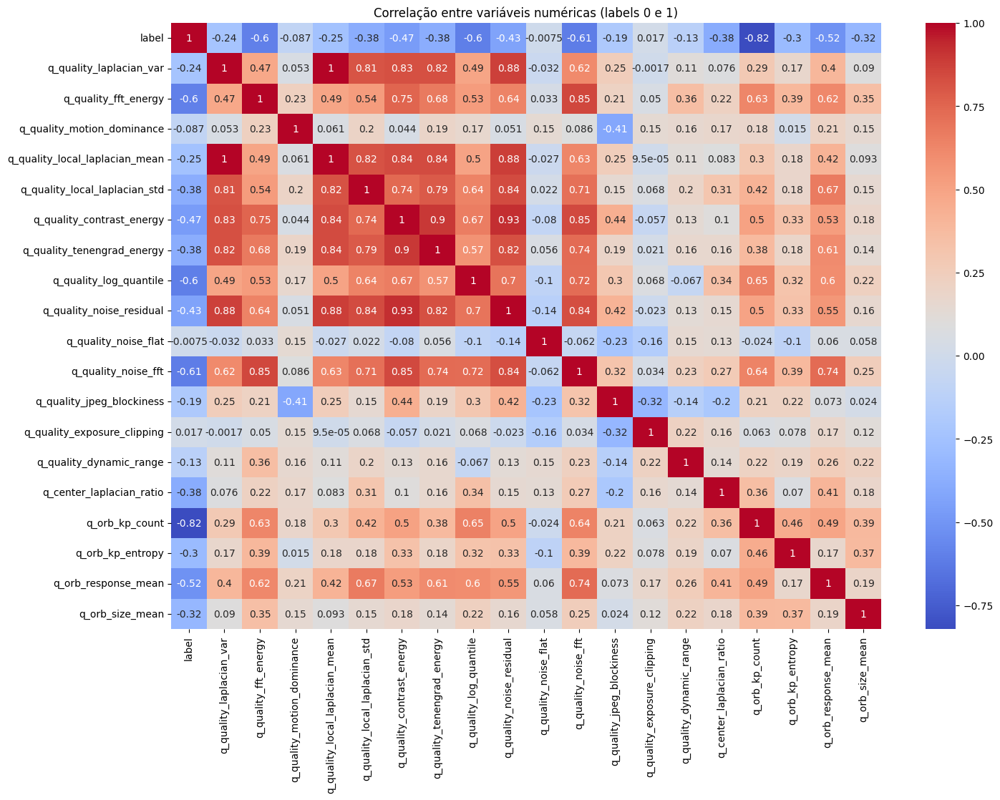

In [ ]:
# Labels existentes
labels = df_random_images_quality["label"].unique()

# Todas as colunas numéricas
numeric_cols = df_random_images_quality.select_dtypes(include=["int64", "float64"]).columns

for l1, l2 in itertools.combinations(labels, 2):
    df_sub = df_random_images_quality[
        df_random_images_quality["label"].isin([l1, l2])
    ]

    corr = df_sub[numeric_cols].corr()

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        corr,
        annot=False,
        cmap="coolwarm",
        center=0,
        square=True,
        linewidths=0.5
    )
    plt.title(f"Matriz de Correlação: {l1} vs {l2}")
    plt.tight_layout()

    # Nome do ficheiro seguro para o sistema de ficheiros
    fname = f"corr_{l1.replace(' ', '_')}_vs_{l2.replace(' ', '_')}.png"

    plt.savefig(OUTPUT_GRAPHICS_CORR, dpi=200) # Opcional
    plt.close()



### 1.6 Relação das variáveis e da label

Média

In [ ]:
label_ref = "Good"  # classe de referência

num_vs_label = []

# médias por label para todas as variáveis numéricas
means = df_random_images_quality.groupby("label")[numeric_cols_random].mean()

for col in numeric_cols_random:
    row = {"variavel": col}

    # média do Good
    media_good = means.loc[label_ref, col]
    row[f"media_{label_ref}"] = media_good

    # médias das restantes classes + diferença em relação ao Good
    for label in means.index:
        if label == label_ref:
            continue

        row[f"media_{label}"] = means.loc[label, col]
        row[f"dif_{label}_vs_{label_ref}"] = means.loc[label, col] - media_good

    num_vs_label.append(row)

num_vs_label = pd.DataFrame(num_vs_label)
num_vs_label



,variavel,media_label_0,media_label_1,diferença
0,label,0.000000,1.000000,1.000000
1,q_quality_laplacian_var,164.682750,53.297062,-111.385688
2,q_quality_fft_energy,12.004175,5.711979,-6.292196
3,q_quality_motion_dominance,1.773247,1.664617,-0.108630
4,q_quality_local_laplacian_mean,179.370545,55.456188,-123.914357
5,q_quality_local_laplacian_std,271.231336,50.249933,-220.981403
6,q_quality_contrast_energy,27.465822,13.609499,-13.856324
7,q_quality_tenengrad_energy,3325.509144,469.829823,-2855.679321
8,q_quality_log_quantile,35.114131,16.338571,-18.775560
9,q_quality_noise_residual,2.393716,1.277902,-1.115813


Mediana

In [ ]:
label_ref = "Good"  # classe de referência

num_vs_label = []

# medianas por label para todas as variáveis numéricas
medians = df_random_images_quality.groupby("label")[numeric_cols_random].median()

for col in numeric_cols_random:
    row = {"variavel": col}

    # mediana do Good
    mediana_good = medians.loc[label_ref, col]
    row[f"mediana_{label_ref}"] = mediana_good

    # medianas das restantes classes + diferença em relação ao Good
    for label in medians.index:
        if label == label_ref:
            continue

        row[f"mediana_{label}"] = medians.loc[label, col]
        row[f"dif_{label}_vs_{label_ref}"] = medians.loc[label, col] - mediana_good

    num_vs_label.append(row)

num_vs_label = pd.DataFrame(num_vs_label)
num_vs_label



,variavel,mediana_label_0,mediana_label_1,diferença
0,label,0.000000,1.000000,1.000000
1,q_quality_laplacian_var,82.563905,24.641823,-57.922081
2,q_quality_fft_energy,10.569834,5.090073,-5.479762
3,q_quality_motion_dominance,1.615391,1.475913,-0.139478
4,q_quality_local_laplacian_mean,90.663946,25.642704,-65.021242
5,q_quality_local_laplacian_std,140.155534,19.631131,-120.524404
6,q_quality_contrast_energy,22.995941,12.347561,-10.648380
7,q_quality_tenengrad_energy,1685.011210,268.035056,-1416.976154
8,q_quality_log_quantile,33.000000,14.000000,-19.000000
9,q_quality_noise_residual,1.975618,1.080137,-0.895480


Máximos e Mínimos

In [ ]:
num_vs_label = []

# mínimos e máximos por label para todas as variáveis numéricas
stats = df_random_images_quality.groupby("label")[numeric_cols_random].agg(["min", "max"])

for col in numeric_cols_random:
    row = {"variavel": col}

    for label in stats.index:
        row[f"min_{label}"] = stats.loc[label, (col, "min")]
        row[f"max_{label}"] = stats.loc[label, (col, "max")]

    num_vs_label.append(row)

num_vs_label = pd.DataFrame(num_vs_label)
num_vs_label


,variavel,min_label_0,max_label_0,min_label_1,max_label_1
0,label,0.000000,0.000000,1.000000,1.000000
1,q_quality_laplacian_var,9.129285,2705.657753,1.249082,4354.166939
2,q_quality_fft_energy,3.209639,37.644891,1.485650,22.968809
3,q_quality_motion_dominance,1.134947,6.492018,1.102918,6.094697
4,q_quality_local_laplacian_mean,9.595831,2910.914800,1.270953,4506.522418
5,q_quality_local_laplacian_std,9.758870,2981.846577,0.912223,2553.427154
6,q_quality_contrast_energy,5.903443,189.943455,2.451801,125.678638
7,q_quality_tenengrad_energy,216.926592,68846.054546,15.792493,25406.461490
8,q_quality_log_quantile,10.000000,95.000000,4.000000,77.000000
9,q_quality_noise_residual,0.675287,11.829343,0.227152,13.342749


Amplitude

In [ ]:
# amplitude (max - min) para todas as labels
num_vs_label = []

# calcula min e max por label para todas as variáveis numéricas
stats = df_random_images_quality.groupby("label")[numeric_cols_random].agg(["min", "max"])

for col in numeric_cols_random:
    row = {"variavel": col}

    for label in stats.index:
        minimo = stats.loc[label, (col, "min")]
        maximo = stats.loc[label, (col, "max")]
        row[f"range_{label}"] = maximo - minimo

    num_vs_label.append(row)

num_vs_label = pd.DataFrame(num_vs_label)
num_vs_label



,variavel,range_label_0,range_label_1
0,label,0.000000,0.000000
1,q_quality_laplacian_var,2696.528468,4352.917857
2,q_quality_fft_energy,34.435252,21.483159
3,q_quality_motion_dominance,5.357071,4.991780
4,q_quality_local_laplacian_mean,2901.318969,4505.251465
5,q_quality_local_laplacian_std,2972.087707,2552.514931
6,q_quality_contrast_energy,184.040012,123.226838
7,q_quality_tenengrad_energy,68629.127954,25390.668997
8,q_quality_log_quantile,85.000000,73.000000
9,q_quality_noise_residual,11.154056,13.115597


Percentis

In [ ]:
# percentis por label + globais
num_vs_label = []

for col in numeric_cols_random:
    # Percentis por label
    stats_label = (
        df_random_images_quality
        .groupby("label")[col]
        .quantile([0.05, 0.95])
        .unstack()
    )
    # stats_label:
    # index -> labels ("Good", "Noisy", ...)
    # columns -> [0.05, 0.95]

    # Percentis globais (todas as imagens)
    stats_global = df_random_images_quality[col].quantile([0.05, 0.95])

    row = {
        "variavel": col,
        "p05_global": stats_global.loc[0.05],
        "p95_global": stats_global.loc[0.95],
    }

    # adiciona percentis para todas as labels existentes
    for label in stats_label.index:
        row[f"p05_{label}"] = stats_label.loc[label, 0.05]
        row[f"p95_{label}"] = stats_label.loc[label, 0.95]

    num_vs_label.append(row)

num_vs_label = pd.DataFrame(num_vs_label)
num_vs_label



,variavel,p05_label_0,p95_label_0,p05_label_1,p95_label_1,p05_global,p95_global
0,label,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000
1,q_quality_laplacian_var,17.099662,564.194597,5.289778,152.588681,6.950674,311.424793
2,q_quality_fft_energy,5.221199,23.639248,2.760230,10.765028,2.965751,17.896612
3,q_quality_motion_dominance,1.235764,2.828315,1.201859,2.778884,1.211410,2.804342
4,q_quality_local_laplacian_mean,18.707166,611.527147,5.512603,157.077476,7.121174,331.808198
5,q_quality_local_laplacian_std,25.642355,932.901987,3.779791,160.078532,4.669141,517.027175
6,q_quality_contrast_energy,11.934676,64.634846,6.129307,23.371385,7.125741,38.642567
7,q_quality_tenengrad_energy,400.128972,11614.227180,77.715702,1120.270825,96.717890,5857.188317
8,q_quality_log_quantile,15.450000,61.550000,6.000000,36.000000,7.000000,51.000000
9,q_quality_noise_residual,0.957250,5.221802,0.512099,2.542375,0.593574,3.714934


Percentis mais completo e max e min

In [ ]:
# percentis completos + min e max por label e também globais
num_vs_label = []

# percentis que queremos calcular
percentis = [0.025, 0.05, 0.10, 0.50, 0.90, 0.95, 0.975]

for col in numeric_cols_random:
    # Estatísticas por label
    stats_label = (
        df_random_images_quality
        .groupby("label")[col]
        .quantile(percentis)
        .unstack()
    )
    # stats_label:
    # index   -> labels ("Good", "Noisy", ...)
    # columns -> [0.025, 0.05, 0.10, 0.50, 0.90, 0.95, 0.975]

    # Min e max por label
    minmax_label = (
        df_random_images_quality
        .groupby("label")[col]
        .agg(["min", "max"])
    )

    # Estatísticas globais
    stats_global = df_random_images_quality[col].quantile(percentis)
    min_global = df_random_images_quality[col].min()
    max_global = df_random_images_quality[col].max()

    row = {
        "variavel": col,
        "min_global": min_global,
        "max_global": max_global,
    }

    # percentis globais
    for p in percentis:
        row[f"p{int(p*1000):03d}_global"] = stats_global.loc[p]

    # percentis + min/max por cada label
    for label in stats_label.index:
        row[f"min_{label}"] = minmax_label.loc[label, "min"]
        row[f"max_{label}"] = minmax_label.loc[label, "max"]

        for p in percentis:
            row[f"p{int(p*1000):03d}_{label}"] = stats_label.loc[label, p]

    num_vs_label.append(row)

num_vs_label = pd.DataFrame(num_vs_label)
num_vs_label


,variavel,p025_label_0,p05_label_0,p10_label_0,p50_label_0,p90_label_0,p95_label_0,p025_label_1,p05_label_1,p10_label_1,p50_label_1,p90_label_1,p95_label_1
0,label,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,q_quality_laplacian_var,1.538931e+01,17.099662,22.837907,82.563905,322.801852,770.600986,3.943874,5.289778,8.063209,24.641823,95.946055,248.212545
2,q_quality_fft_energy,4.706748e+00,5.221199,6.604029,10.569834,19.150733,26.994039,2.399137,2.760230,3.196260,5.090073,8.887582,12.414933
3,q_quality_motion_dominance,1.209301e+00,1.235764,1.276609,1.615391,2.453046,3.162066,1.177964,1.201859,1.241161,1.475913,2.275360,3.420524
4,q_quality_local_laplacian_mean,1.682718e+01,18.707166,25.227037,90.663946,360.805559,844.492855,4.189627,5.512603,8.214027,25.642704,97.951369,256.112693
5,q_quality_local_laplacian_std,2.145195e+01,25.642355,32.824622,140.155534,581.360839,1511.355906,2.641947,3.779791,5.504016,19.631131,99.046847,247.023952
6,q_quality_contrast_energy,1.047834e+01,11.934676,13.730080,22.995941,44.908105,73.940975,5.032382,6.129307,7.783483,12.347561,19.787772,27.068386
7,q_quality_tenengrad_energy,3.377176e+02,400.128972,559.447541,1685.011210,6899.158657,15932.922299,55.974129,77.715702,105.796227,268.035056,758.056177,1850.209384
8,q_quality_log_quantile,1.300000e+01,15.450000,18.900000,33.000000,53.100000,66.275000,6.000000,6.000000,7.000000,14.000000,27.000000,45.525000
9,q_quality_noise_residual,8.895138e-01,0.957250,1.069207,1.975618,3.950275,6.103283,0.442834,0.512099,0.646556,1.080137,2.047434,3.273124


Quais as features mais discriminativas:
* valores positivos grandes → separação limpa
* valores negativos → overlap forte

In [ ]:
label_ref = "Good"

# lista de labels existentes
labels = [l for l in num_vs_label.columns if l.startswith("p05_")]
labels = [l.replace("p05_", "") for l in labels if not l.endswith("_global")]

# remove o Good da lista (não faz sentido comparar Good com Good)
labels = [l for l in labels if l != label_ref]

dfs_separacao = {}

for label in labels:
    df_sep = num_vs_label.copy()

    col_p05_label = f"p05_{label}"
    col_p95_good = f"p95_{label_ref}"

    df_sep["separacao"] = df_sep[col_p05_label] - df_sep[col_p95_good]

    # ordenar da mais discriminativa para a menos
    df_sep = df_sep.sort_values("separacao", ascending=False)

    dfs_separacao[f"{label}_vs_{label_ref}"] = df_sep


,variavel,p05_label_0,p95_label_0,p05_label_1,p95_label_1,separacao
0,label,0.000000,0.000000,1.000000,1.000000,1.000000
18,q_orb_response_mean,0.000096,0.005857,0.000000,0.000271,-0.005857
13,q_quality_exposure_clipping,0.000005,0.142519,0.000000,0.154945,-0.142519
10,q_quality_noise_flat,0.000000,1.210557,0.000000,1.164584,-1.210557
3,q_quality_motion_dominance,1.235764,2.828315,1.201859,2.778884,-1.626456
17,q_orb_kp_entropy,0.868278,2.290079,0.000000,2.222721,-2.290079
15,q_center_laplacian_ratio,0.508732,3.988432,0.398624,1.875776,-3.589808
9,q_quality_noise_residual,0.957250,5.221802,0.512099,2.542375,-4.709703
2,q_quality_fft_energy,5.221199,23.639248,2.760230,10.765028,-20.879017
19,q_orb_size_mean,53.735771,53.735771,0.000000,89.457497,-53.735771


In [ ]:
dfs_separacao["Noisy_vs_Good"]
dfs_separacao["Very Noisy_vs_Good"]
dfs_separacao["Pixelated_vs_Good"]
dfs_separacao["Motion Blur_vs_Good"]
dfs_separacao["Defocused Blur_vs_Good"]


In [ ]:
# quiseres apenas ver as 10 melhores features para cada classe:
for nome, df in dfs_separacao.items():
    print(f"\nTop features para {nome}:")
    display(df[["variavel", "separacao"]].head(10))


### Conclusões


u fat